In [9]:
#Bolli Yaswanth Melki , 92400133114 , 5EK2B , DecisionTree

In [10]:
import os
import pandas as pd

TEMPS_PATH = "/content/temps.csv"

if not os.path.exists(TEMPS_PATH):
    try:
        from google.colab import files
        print("Upload 'temps.csv':")
        uploaded = files.upload()
        TEMPS_PATH = next(iter(uploaded.keys()))
    except ImportError:
        raise FileNotFoundError(f"{TEMPS_PATH} not found.")

features = pd.read_csv(TEMPS_PATH)
print("Shape:", features.shape)
features.head()

Shape: (348, 12)


,year,month,day,week,temp_2,temp_1,average,actual,forecast_noaa,forecast_acc,forecast_under,friend
0,2016,1,1,Fri,45,45,45.6,45,43,50,44,29
1,2016,1,2,Sat,44,45,45.7,44,41,50,44,61
2,2016,1,3,Sun,45,44,45.8,41,43,46,47,56
3,2016,1,4,Mon,44,41,45.9,40,44,48,46,53
4,2016,1,5,Tues,41,40,46.0,44,46,46,46,41


In [11]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

features_encoded = pd.get_dummies(features)
labels = np.array(features_encoded["actual"])
X_df = features_encoded.drop("actual", axis=1)
feature_names = list(X_df.columns)
X = np.array(X_df)

X_tr, X_te, y_tr, y_te = train_test_split(
    X, labels, test_size=0.25, random_state=42
)

reg = DecisionTreeRegressor(max_depth=4, random_state=42)
reg.fit(X_tr, y_tr)
preds = reg.predict(X_te)

mae = mean_absolute_error(y_te, preds)
rmse = np.sqrt(mean_squared_error(y_te, preds))
mape = 100.0 * np.mean(np.abs(preds - y_te) / y_te)

print(
    f"MAE: {mae:.2f} deg | RMSE: {rmse:.2f} deg | "
    f"Accuracy (100 - MAPE): {100 - mape:.2f}% | R^2: {r2_score(y_te, preds):.4f}"
)

MAE: 3.98 deg | RMSE: 5.26 deg | Accuracy (100 - MAPE): 93.78% | R^2: 0.8010


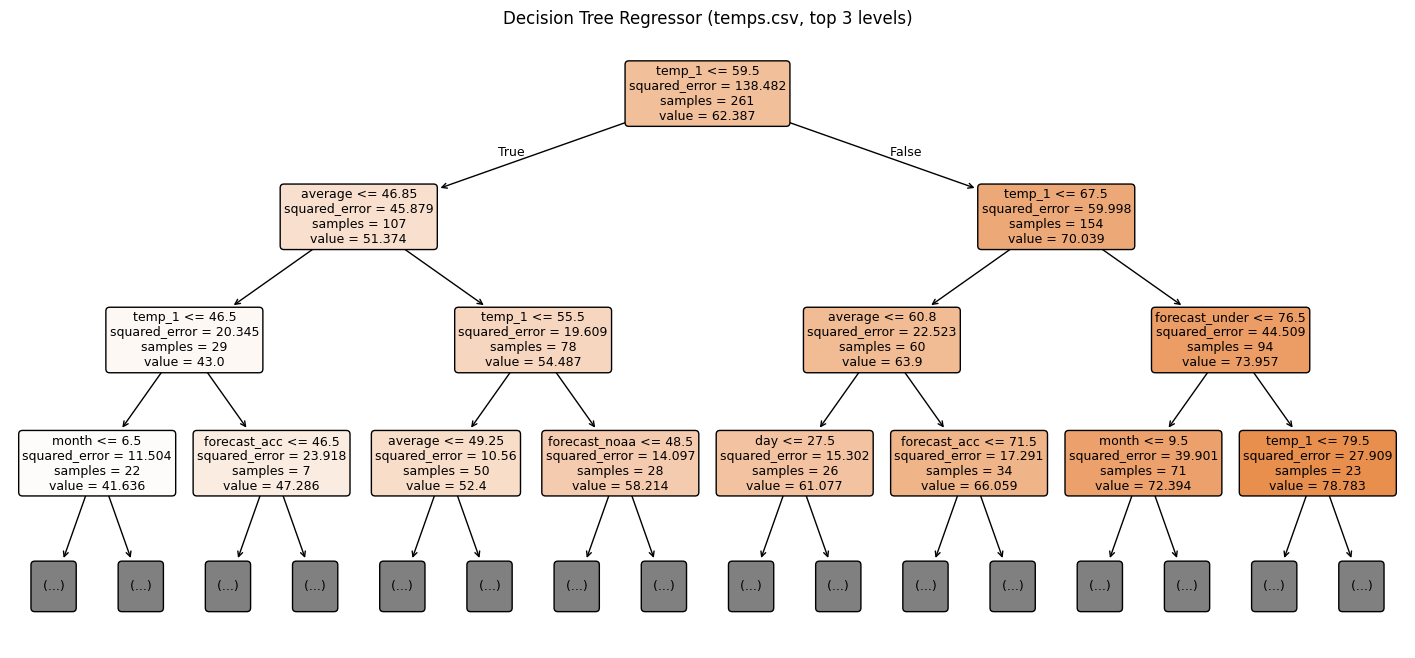

Top Feature Importances:
temp_1            0.843887
average           0.103622
forecast_under    0.022379
month             0.016177
forecast_acc      0.006332
forecast_noaa     0.004325
day               0.003278
year              0.000000
dtype: float64


In [12]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(18, 8))
plot_tree(
    reg,
    feature_names=feature_names,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9,
)
plt.title("Decision Tree Regressor (temps.csv, top 3 levels)")
plt.show()

importances = pd.Series(
    reg.feature_importances_, index=feature_names
).sort_values(ascending=False)
print("Top Feature Importances:")
print(importances.head(8))

Random Forest


In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [15]:
features=pd.read_csv('temps.csv')
features.head(5)
features.shape
features.describe()
features=pd.get_dummies(features)
features.head(5)
features.shape
labels=np.array(features['actual'])
features=features.drop('actual',axis=1)
features
feature_list=list(features.columns)
features=np.array(features)
from sklearn.model_selection import train_test_split
train_features,test_features,train_labels,test_labels=train_test_split(features,labels,test_size=0.25,random_state=42)
test_labels.shape
from sklearn.ensemble import RandomForestRegressor
rf=RandomForestRegressor(n_estimators=1000,random_state=42)
rf.fit(train_features,train_labels)
predictions=rf.predict(test_features)
errors=abs(predictions-test_labels)

In [16]:
#Mean absolute percentage error
mape=100*(errors/test_labels)

mean_error=np.mean(mape)
accuracy=100-mean_error
accuracy
from sklearn.tree import export_graphviz
import pydot
tree=rf.estimators_[5]
export_graphviz(tree,out_file='tree.dot',feature_names=feature_list,rounded=True,precision=1)
(graph,)=pydot.graph_from_dot_file('tree.dot')
graph.write_png('tree.png');

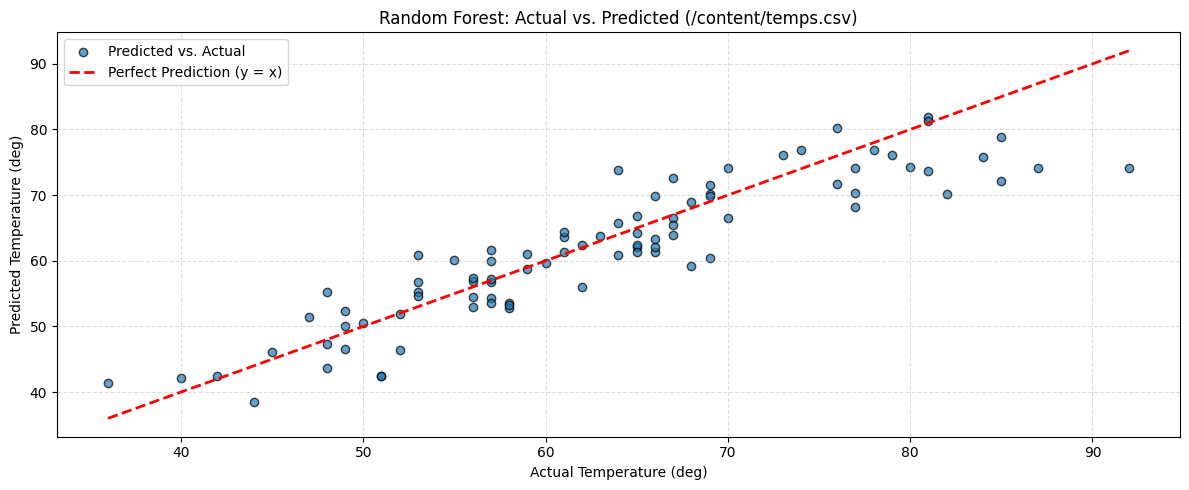

In [17]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(12, 5))
plt.scatter(test_labels, predictions, alpha=0.7, edgecolors="k", label="Predicted vs. Actual")
min_val = min(np.min(test_labels), np.min(predictions))
max_val = max(np.max(test_labels), np.max(predictions))
plt.plot([min_val, max_val], [min_val, max_val], "r--", linewidth=2, label="Perfect Prediction (y = x)")

plt.xlabel("Actual Temperature (deg)")
plt.ylabel("Predicted Temperature (deg)")
plt.title("Random Forest: Actual vs. Predicted (/content/temps.csv)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

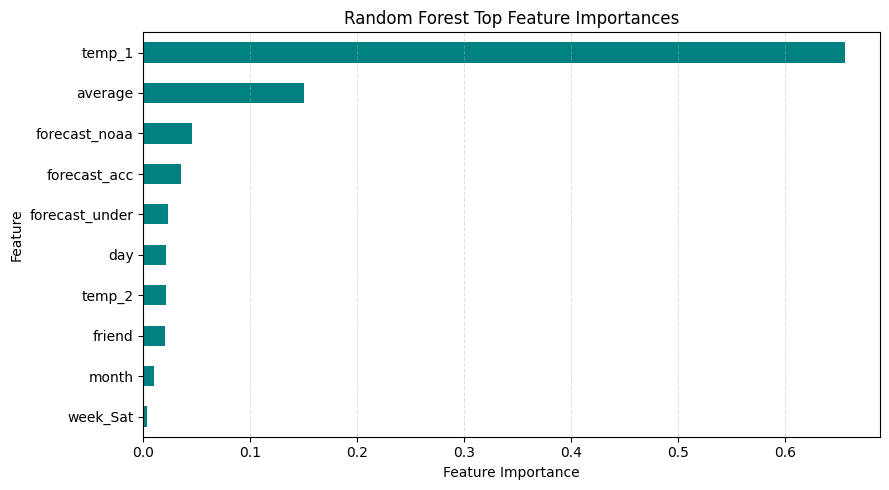

In [18]:
import matplotlib.pyplot as plt
import pandas as pd

importances = pd.Series(rf.feature_importances_, index=feature_list).sort_values(ascending=True)

plt.figure(figsize=(9, 5))
importances.tail(10).plot(kind="barh", color="teal")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest Top Feature Importances")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

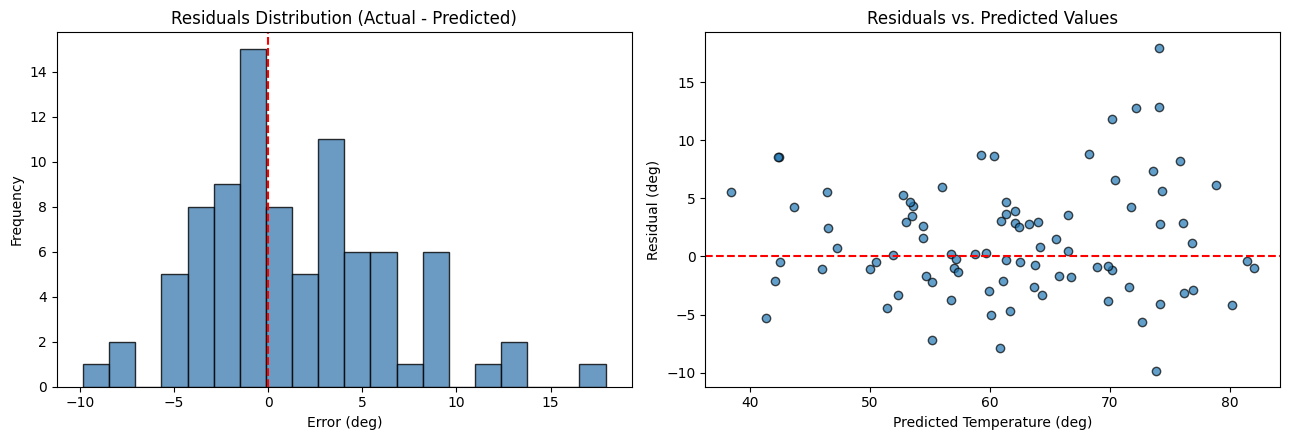

In [19]:
import matplotlib.pyplot as plt
import numpy as np

residuals = test_labels - predictions

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(residuals, bins=20, color="steelblue", edgecolor="black", alpha=0.8)
axes[0].axvline(0, color="red", linestyle="--", linewidth=1.5)
axes[0].set_title("Residuals Distribution (Actual - Predicted)")
axes[0].set_xlabel("Error (deg)")
axes[0].set_ylabel("Frequency")

axes[1].scatter(predictions, residuals, alpha=0.7, edgecolors="k")
axes[1].axhline(0, color="red", linestyle="--", linewidth=1.5)
axes[1].set_title("Residuals vs. Predicted Values")
axes[1].set_xlabel("Predicted Temperature (deg)")
axes[1].set_ylabel("Residual (deg)")

plt.tight_layout()
plt.show()